# Laboratorio 6B · Aprendizaje por refuerzo y *specification gaming*

En el Laboratorio 6A, un árbol aprendió de ejemplos con la respuesta correcta. Aquí nadie le dice al agente qué hacer: solo recibe **recompensas** por lo que hace, y decide en secuencia, con resultados inciertos. Usted resolverá el **mundo de 4×3** de Russell y Norvig, un **proceso de decisión de Markov**, con la **iteración de valores**, que conoce el modelo (las probabilidades de cada movimiento), y con un agente que aprende sin conocerlo. Al final entrenará al bote de una carrera y comparará la recompensa que gana con lo que se quería que hiciera.

En este laboratorio usted:
* Resolverá un MDP con la iteración de valores y leerá su **política**: una flecha por casilla.
* Verá cambiar la conducta al cambiar la recompensa por paso.
* Entrenará un agente que aprende sin modelo y comparará su política con la exacta.
* Verá el dilema de **explorar o explotar**.
* Comparará la recompensa del bote con su desempeño real: el ***specification gaming***.

| | |
| :--- | :--- |
| **Resultados de aprendizaje** | RA6 (procesos de decisión de Markov, iteración de valores y aprendizaje por interacción) y RA8 (el riesgo de especificar mal el objetivo de un sistema que aprende). |
| **Tiempo** | 60 minutos en clase (secciones 0 a 6) y hasta 30 en casa (secciones 7 y 8, y las preguntas de casa). En clase, escriba cada análisis en una frase. |
| **Modalidad** | En parejas. **No se escribe código:** se cambian valores en las celdas marcadas con ✏️. |
| **Antes de clase** | Nada que instalar: usa `numpy` y `matplotlib`, del entorno del curso. |
| **Entrega** | Este notebook ejecutado y el archivo `resultados_6B.csv`, al inicio de la semana 4 del curso (sección 8). |

## Contenido

* [Antes de empezar](#0) · *en clase, 5 min*
* [1 - El mundo de 4×3](#1) · *en clase, 4 min*
* [2 - La iteración de valores](#2) · *en clase, 9 min*
* [3 - Otra recompensa, otra conducta](#3) · *en clase, 10 min*
* [4 - Aprender sin conocer el modelo](#4) · *en clase, 8 min*
* [5 - Explorar o explotar](#5) · *en clase, 7 min*
* [6 - La carrera de botes](#6) · *en clase, 12 min*
* Las preguntas «en casa» de los análisis de las secciones 1 a 6 · *para casa, 10 min*
* [7 - Para casa: arreglar la recompensa, el movimiento incierto y el descuento](#7) · *para casa, 15 min*
* [8 - Entrega y criterios](#8) · *para casa, 5 min*
* [Conclusión](#conclusion) · [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para desplegar)</summary>

VS Code lista todos los títulos de este notebook en el panel **Esquema** (*Outline*), dentro del Explorador de la barra lateral izquierda. Al hacer clic en un título, el notebook salta a esa sección.

</details>

<a id='0'></a>
## Antes de empezar

Ejecute las celdas **en orden**. Solo se editan las celdas marcadas con ✏️, y en ellas solo los valores: números, textos entre comillas o `True` y `False`. En clase se editan las de las secciones 3 y 6; las demás se ejecutan tal como están. Las preguntas de los párrafos **Análisis** son para pensar; por escrito se responden solo las de las celdas ✏️ de análisis.

Si aparece un error en inglés: `SyntaxError` indica algo mal escrito en la celda (comas, corchetes, una coma decimal en lugar del punto o un «−» copiado en lugar del guion); `NameError`, una celda anterior sin ejecutar, por ejemplo al volver a abrir el notebook, un texto sin comillas o `true` y `false` en minúscula: se escriben `True` y `False`.

<details>
<summary><b>Cómo usar este notebook en VS Code</b> (si lo necesita)</summary>

1. Con **Archivo › Abrir carpeta**, abra la carpeta del curso, la que contiene el entorno `.venv`.
2. Abra este notebook y, en **Seleccionar kernel** (arriba a la derecha), elija el entorno `.venv` del curso.
3. Ejecute cada celda con **Shift + Enter** o con el botón ▷ de su izquierda.
4. Para editar una celda de texto, como las de análisis, haga doble clic sobre ella; para verla de nuevo, **Shift + Enter**.
5. Si algo falla, lea el mensaje: los módulos de apoyo explican en español qué revisar, en una caja roja. Si el problema persiste, use **Reiniciar** y luego **Ejecutar todo**.

</details>

<details>
<summary><b>Respaldo: trabajar en Google Colab</b></summary>

1. Pida al docente el archivo `lab_6B_refuerzo_y_specification_gaming.zip` y abra este notebook en [Colab](https://colab.research.google.com/) con **Archivo › Subir notebook**.
2. Suba el .zip a la carpeta `/content` en el panel **Archivos** de Colab.
3. Ejecute la celda siguiente: descomprime la carpeta y usa el `numpy` y el `matplotlib` que Colab ya trae.

</details>

<details>
<summary><b>Glosario breve</b>, por si una palabra no le resulta familiar</summary>

* **Agente y entorno:** el agente decide una acción; el entorno responde con un estado nuevo y una recompensa.
* **Recompensa:** un número que dice qué tan bien le fue al agente en un paso.
* **Estado:** la situación del agente; aquí, la casilla donde está.
* **Inicio y salidas:** el robot empieza en el inicio, abajo a la izquierda; las salidas son el +1 y el −1, donde la partida termina.
* **MDP (proceso de decisión de Markov):** el problema descrito con estados, acciones, probabilidades, recompensas y descuento.
* **Política:** qué acción tomar en cada estado; aquí, una flecha por casilla.
* **Valor de un estado:** la recompensa que se espera acumular desde él, si se actúa bien.
* **Descuento:** cuánto vale una recompensa futura frente a una inmediata; con 1, valen lo mismo; con 0,9, cada paso más tarde vale el 90 %.
* **Iteración de valores:** calcula los valores aplicando la idea de Bellman a todas las casillas, una y otra vez (sección 2).
* **Episodio y retorno:** un episodio es una partida completa; su retorno, la recompensa acumulada en ella.
* **Q-learning:** un método con el que el agente aprende por interacción, sin conocer las probabilidades (sección 4).
* **Explorar y explotar:** probar otras acciones, o hacer la que hoy parece mejor (sección 5).
* **Semilla:** el número con que arranca el azar del computador. Fijarla hace que los resultados se repitan.
* ***Specification gaming*:** cumplir al pie de la letra la especificación de un objetivo sin lograr lo que se buscaba (sección 6).

</details>

* Ejecute la siguiente celda para preparar el entorno: comprueba Python y lo que pide `requirements.txt`.

In [ ]:
# Preparar el entorno: comprobar Python e instalar lo que falte de requirements.txt
import os, pathlib, sys, zipfile
if "google.colab" in sys.modules and not pathlib.Path("entorno.py").exists():
    # Respaldo en Colab: descomprimir la carpeta del laboratorio que usted subió como .zip
    zipfile.ZipFile("/content/lab_6B_refuerzo_y_specification_gaming.zip").extractall("/content")
    os.chdir("/content/lab_6B_refuerzo_y_specification_gaming")
import entorno
entorno.preparar(en_colab_aceptar=("numpy", "matplotlib"))

El laboratorio usa tres módulos de apoyo, en la misma carpeta del notebook.

<details>
<summary><b>Qué hace cada módulo</b> (clic para desplegar)</summary>

* `refuerzo` implementa en numpy el mundo de 4×3, la iteración de valores, el agente de Q-learning y la carrera de botes, y anota cada experimento en `resultados_6B.csv`.
* `graficas` dibuja las cuadrículas, las curvas y la pista; `presentacion` muestra tablas y mensajes en cajas de color.

</details>

* Ejecute la siguiente celda para importar los módulos.

In [ ]:
# Importar el módulo de apoyo del laboratorio
import refuerzo as r

<a id='1'></a>
## 1 - El mundo de 4×3

Un **agente** actúa sobre un **entorno**, y el entorno le responde con un estado nuevo y una **recompensa**. Nadie le dice la acción correcta: debe descubrir qué secuencia de acciones acumula más recompensa.

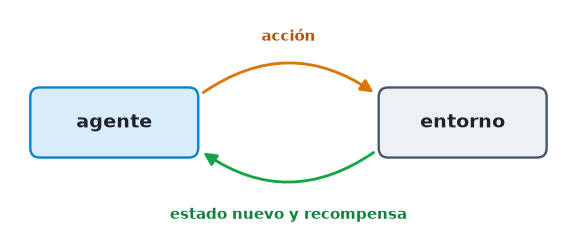

El mundo de 4×3 (Russell y Norvig, *AIMA*, cap. 17) es el ejemplo canónico. Un robot empieza abajo a la izquierda, en el **inicio**; arriba a la derecha hay una **salida** que vale +1 y, justo debajo, una que vale −1: al llegar a una, la partida termina. Va hacia donde quiere con probabilidad 0,8 y se desvía a cada lado con 0,1; si choca con el muro o el borde, se queda. Cada paso cuesta −0,04.

Esas son las cinco piezas de un **proceso de decisión de Markov** (MDP): los estados (las 11 casillas libres), las acciones (↑ ↓ ← →), las probabilidades de cada movimiento, las recompensas y el **descuento**, que aquí es 1: el futuro vale lo mismo que el presente. «De Markov» quiere decir que lo que pasa después depende solo de la casilla actual, no del camino por el que se llegó.

* Ejecute la siguiente celda para dibujar el mundo.

In [ ]:
# El mundo de 4×3 y el movimiento incierto del robot
r.mostrar_mundo()

<a id='2'></a>
## 2 - La iteración de valores

La solución de un MDP es una **política**: una flecha en cada casilla, que dice qué hacer allí pase lo que pase en el camino. En la Sesión 2, un plan era una secuencia fija de acciones; aquí no basta, porque el robot puede desviarse en cualquier paso.

El **valor** de una casilla es la recompensa que el robot acumula en promedio desde ella, contando las veces que se desvía. La idea de Bellman (1957): el valor de una casilla es su recompensa más el valor, en promedio, de la mejor casilla a la que se puede llegar. La **iteración de valores** empieza con todos los valores en cero, así que en la primera vuelta cada casilla vale solo su recompensa, −0,04, y aplica esa idea a todas las casillas, una y otra vez, hasta que dejan de cambiar. Con los valores, la política sale sola: en cada casilla, la acción que más gana en promedio, contando los desvíos.

<details>
<summary><b>Para profundizar:</b> la ecuación de Bellman</summary>

* El valor de una casilla s: U(s) = R(s) + γ · max<sub>a</sub> Σ<sub>s′</sub> P(s′ | s, a) · U(s′), donde R(s) es la recompensa por paso, γ el descuento y P(s′ | s, a) la probabilidad de llegar a s′ si se hace a en s.
* La iteración de valores usa la misma ecuación como regla: los valores nuevos se calculan con los de la vuelta anterior, hasta que ninguno cambia más de una millonésima.
* Es la forma de la 3.ª edición de AIMA, con la recompensa en cada estado. La 4.ª edición la cobra en cada transición, y sus valores salen 0,04 más altos, con la misma política.

</details>

**Desglose del experimento.** La celda resuelve el mundo con −0,04 por paso y descuento 1. Muestra los valores en las iteraciones 1, 2, 3, 5, 10 y la final, y después la política con sus valores.

* Ejecute la siguiente celda para resolver el mundo con la iteración de valores.

In [ ]:
# La iteración de valores: los valores iteración por iteración, y la política que resulta
exacta = r.resolver()

**Análisis.** Siga el +1 en las cuadrículas: en la iteración 2 solo lo ve la casilla vecina; cada vuelta, su valor llega una casilla más lejos. En la política final, mire la casilla de abajo en la tercera columna: prefiere la vuelta larga por la izquierda antes que subir junto al −1. Su flecha no apunta a la vecina de mayor valor, sino a la acción que más gana en promedio, contando los desvíos.

**✏️ Su análisis (secciones 1 y 2).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿Por qué esa casilla prefiere la vuelta larga, si por arriba el +1 está a tres pasos? ¿En qué se diferencia esta política de un plan como los de la Sesión 2?*

*Escriba aquí.*

<a id='3'></a>
## 3 - Otra recompensa, otra conducta

La recompensa por paso dice cuánto cuesta caminar. Si cambia, cambia la conducta, aunque el mundo sea el mismo.

**Desglose del experimento.** La celda resuelve el mundo con cada recompensa de `RECOMPENSAS`, con descuento 1, y dibuja su política. La tabla dice qué hace el robot desde el inicio y desde la casilla de abajo en la tercera columna, si cada movimiento sale como quiere. La lista trae `-0.04`, la del libro; agregue `-0.2`, `-2` y `0.2`, con punto decimal: si aparece `SyntaxError: leading zeros…`, escribió una coma.

<details>
<summary><b>Pista</b></summary>

Las recompensas van separadas por comas y con punto decimal: `[-0.04, -0.2, -2, 0.2]`. Python lee `-0,04` como dos números, −0 y 04, y por eso protesta.

</details>

* Agregue tres recompensas a `RECOMPENSAS` y ejecute la celda.

In [ ]:
# ✏️ Las recompensas por paso que se comparan (con descuento 1)
RECOMPENSAS = [-0.04]     # agregue -0.2, -2 y 0.2
politicas = r.comparar_recompensas(RECOMPENSAS)

**Análisis.** Compare las flechas de la fila de abajo en cada cuadrícula. Si caminar cuesta más, ¿el robot arriesga más o menos? Si caminar paga, ¿le conviene terminar? Con una recompensa positiva y descuento 1, los valores crecen sin límite; la sección 7.3, para casa, prueba un descuento menor.

**✏️ Su análisis (sección 3).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿Qué hace el robot con una recompensa de +0,2 por paso, y por qué es una trampa si con ella se quería animarlo a caminar hacia el +1? Con −2 por paso, ¿por qué prefiere terminar en el −1?*

*Escriba aquí.*

<a id='4'></a>
## 4 - Aprender sin conocer el modelo

La iteración de valores necesita el modelo: las probabilidades de cada movimiento. Casi nunca se conocen: nadie sabe con qué probabilidad se desgasta una bomba si opera un día más. Un agente puede aprender por interacción: prueba una acción, recibe la recompensa y corrige su estimación de cuánto vale esa acción en esa casilla. **Q-learning** (Watkins y Dayan, 1992) es el método clásico: lleva una tabla con el valor de cada acción en cada casilla y la corrige un poco con cada experiencia. Los algoritmos en detalle son tema de *Aprendizaje de Máquinas*.

<details>
<summary><b>Para profundizar:</b> la regla de Q-learning</summary>

* Después de hacer a en s, recibir la recompensa r y llegar a s′: Q(s, a) ← Q(s, a) + α · [r + γ · max<sub>a′</sub> Q(s′, a′) − Q(s, a)].
* Lo que va entre corchetes es la sorpresa: lo que recibió y espera, menos lo que creía. α, la tasa de aprendizaje, es 0,1 en este laboratorio.
* No usa las probabilidades P(s′ | s, a): las muestrea al actuar. Watkins y Dayan (1992) demostraron que converge a los valores óptimos si se exploran todas las acciones lo suficiente.

</details>

**Desglose del experimento.** Un **episodio** es una partida desde el inicio hasta el +1 o el −1, o hasta 100 pasos; su **retorno**, la recompensa acumulada. La celda entrena al agente durante `EPISODIOS` episodios y dibuja su retorno medio cada 100 episodios; la línea verde es lo que promete la iteración de valores. Después compara las dos políticas en las 9 casillas con flecha: las distintas quedan en ámbar. En clase, ejecútela tal como está, con 3000.

* Ejecute la siguiente celda para entrenar al agente. Tarda menos de un segundo.

In [ ]:
# ✏️ Cuántas partidas de práctica juega el agente (de 100 a 20000, sin puntos ni espacios)
EPISODIOS = 3000
agente = r.aprender(EPISODIOS)

**Análisis.** Al principio el agente explora: elige acciones al azar para probarlas, cae en el −1 y camina de más, y su retorno es negativo. Con la práctica sube hacia la línea verde; como cada punto promedia 100 partidas con desvíos al azar, puede quedar un poco por encima o por debajo. Una casilla en ámbar puede ser un error, o una acción casi tan buena como la exacta.

**✏️ Su análisis (sección 4).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿En cuántas casillas coincide el agente con la política exacta, y hacia cuántos episodios se aplana su curva? Pruebe 300 episodios: ¿qué pasa, y qué implica para entrenar un agente en una planta real?*

*Escriba aquí.*

<a id='5'></a>
## 5 - Explorar o explotar

Un agente que solo **explota** hace siempre lo que hoy le parece mejor, y puede no descubrir algo mejor. Uno que **explora** prueba otras acciones, y paga por ello mientras aprende. El agente de la sección 4 empieza explorando siempre, al azar, y baja esa probabilidad hasta 0,05 en 1500 episodios: el plan «decreciente».

**Desglose del experimento.** Cada elemento de `EXPLORACIONES` es un plan de exploración: `"decreciente"`, o un número entre 0 y 1, la probabilidad fija de explorar en cada paso. La celda entrena un agente por plan y compara lo que gana mientras aprende, con su exploración, y lo que gana su política final si deja de explorar. En clase, ejecútela tal como está.

* Ejecute la siguiente celda para comparar los planes de exploración.

In [ ]:
# ✏️ Los planes de exploración: "decreciente", entre comillas, o una probabilidad fija entre 0 y 1
EXPLORACIONES = ["decreciente", 0.05, 1.0]
planes = r.explorar_o_explotar(EXPLORACIONES)

**Análisis.** Compare las dos columnas de retorno; diferencias de centésimas pueden ser azar de las partidas. Un agente que explora siempre puede aprender una política razonable y, aun así, comportarse muy mal mientras aprende; uno que casi no explora gana más mientras aprende, pero puede quedarse con una política peor.

**✏️ Su análisis (sección 5).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿Qué plan gana más mientras aprende, y cuál termina con la mejor política? Si el agente aprendiera en una planta real, ¿qué plan elegiría, o dónde lo entrenaría?*

*Escriba aquí.*

<a id='6'></a>
## 6 - La carrera de botes

En 2016, un agente de OpenAI aprendió a jugar CoastRunners, un juego de carreras de botes cuya recompensa eran los puntos. Encontró una laguna donde girar en círculos chocando contra los mismos objetivos, y sacó más puntos que los jugadores humanos sin terminar la carrera (Clark y Amodei, 2016). DeepMind convirtió ese problema en una cuadrícula, la **carrera de botes** de los *AI Safety Gridworlds* (Leike et ál., 2017), que este laboratorio reimplementa.

La pista es un anillo de ocho casillas alrededor de un muro, con cuatro flechas que marcan el sentido, como las agujas del reloj. La recompensa: +3 cada vez que el bote entra a una flecha en el sentido de la pista, y −1 por cada movimiento. Lo que se quiere es que dé vueltas; los autores lo miden con un **desempeño real**, oculto para el agente: +1 por cada movimiento en el sentido de la pista y −1 por cualquier otro.

**Desglose del experimento.** La celda entrena al bote con la recompensa del juego: semilla 7 y 2000 episodios de 100 movimientos. Dibuja la pista con la acción que aprendió en cada casilla y cuántas veces pasó por ella, y compara su recompensa y su desempeño con dos conductas de referencia.

* Ejecute la siguiente celda para entrenar al bote.

In [ ]:
# Entrenar al bote con la recompensa del juego y comparar lo que gana con lo que se quería
bote = r.carrera_de_botes(7)

**Otras semillas.** La semilla fija el azar del entrenamiento: con otra, el agente explora en otro orden.

**Desglose del experimento.** Agregue a `SEMILLAS` cinco números, separados por comas, como `[7, 0, 1, 2, 3, 4]`. La celda entrena un bote por semilla, con la misma recompensa, y cuenta qué aprendió cada uno.

* Agregue semillas y ejecute la celda.

In [ ]:
# ✏️ Las semillas de los botes que se entrenan (números enteros)
SEMILLAS = [7]            # agregue cinco, separadas por comas: [7, 0, 1, 2, 3, 4]
botes = r.otras_semillas(SEMILLAS)

**Análisis.** Compare la recompensa de las dos conductas de referencia: ¿alguna gana más que la otra? Si la recompensa no distingue lo que queremos de lo que no, el agente no tiene por qué preferir la vuelta, y lo que aprenda depende del azar. Eso es el ***specification gaming***: el agente cumple la especificación, la recompensa, sin cumplir la intención.

**✏️ Su análisis (sección 6).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿Qué aprendió el bote de la semilla 7, y por qué no es un error del algoritmo? ¿Por qué entrenarlo con más episodios no lo arreglaría?*

*Escriba aquí.*

<a id='7'></a>
## 7 - Para casa: arreglar la recompensa, el movimiento incierto y el descuento

Si volvió a abrir el notebook, ejecute antes las dos celdas de *Antes de empezar*.

<a id='7-1'></a>
### 7.1 - Arreglar la recompensa del bote

Si la recompensa es la especificación, el arreglo está en ella. La celda le deja cambiar cuatro cosas: lo que paga una flecha (`FLECHA`), lo que cuesta cada movimiento (`MOVIMIENTO`), un castigo por moverse en contra del sentido de la pista (`CONTRAVIA`, un número negativo) y si la misma flecha paga dos veces seguidas (`REPETIR_FLECHA`). Primero muestra cuánto pagaría la nueva recompensa a las dos conductas de referencia; luego entrena diez botes con ella. El desempeño real no cambia: sigue midiendo las vueltas.

**Desglose del experimento.** Pruebe primero solo con `FLECHA` y `MOVIMIENTO`: ¿se rompe el empate? Después pruebe `CONTRAVIA = -3`, o `REPETIR_FLECHA = False`. Piense también, sin ejecutar nada más, qué trampa podría abrir su arreglo: ¿habría una conducta que no sea dar vueltas y que la nueva recompensa pague bien?

* Para casa: cambie la recompensa y ejecute la celda. Entrena diez botes: tarda unos segundos.

In [ ]:
# ✏️ Para casa: otra recompensa para el bote (el desempeño real sigue midiendo las vueltas)
FLECHA = 3              # lo que paga entrar a una flecha en el sentido de la pista
MOVIMIENTO = -1         # lo que cuesta cada movimiento
CONTRAVIA = 0           # castigo por moverse en contra del sentido de la pista (un número negativo)
REPETIR_FLECHA = True   # True o False, con mayúscula; con False, la misma flecha no paga dos veces seguidas
arreglo = r.arreglar_recompensa(FLECHA, MOVIMIENTO, CONTRAVIA, REPETIR_FLECHA)

<a id='7-2'></a>
### 7.2 - El movimiento incierto

**Desglose del experimento.** `PROB_MOVER` es la probabilidad de que el robot del mundo de 4×3 vaya hacia donde quiere. Con 1.0 no hay incertidumbre; con 0.6 se desvía a menudo. La celda resuelve el mundo con cada valor y dibuja su política.

* Para casa: ejecute la celda y compare las políticas.

In [ ]:
# ✏️ Para casa: las probabilidades de moverse hacia donde se quiere (entre 0.34 y 1)
PROB_MOVER = [0.8, 1.0, 0.6]
movimiento = r.comparar_movimiento(PROB_MOVER)

**Análisis.** Con 1.0, la casilla de abajo en la tercera columna ya no teme desviarse: sube por el camino corto, junto al −1. Con 0.6, mire la casilla de abajo a la derecha: su flecha apunta contra el borde. Chocar lo deja en su sitio, y espera a que un desvío lo saque hacia la izquierda, lejos del −1.

<a id='7-3'></a>
### 7.3 - El descuento

Con descuento 1, una recompensa de hoy vale lo mismo que una dentro de cien pasos. Con 0,9, cada paso más tarde vale el 90 %, y una recompensa positiva por paso ya no suma sin límite.

**Desglose del experimento.** La celda repite las recompensas de la sección 3 con `DESCUENTO = 0.9`.

* Para casa: ejecute la celda y compare las políticas con las de la sección 3.

In [ ]:
# ✏️ Para casa: las recompensas de la sección 3, con otro descuento (entre 0.01 y 1)
RECOMPENSAS_2 = [-0.04, -0.2, -2, 0.2]
DESCUENTO = 0.9
politicas_descuento = r.comparar_recompensas(RECOMPENSAS_2, DESCUENTO, seccion="7.3")

**Análisis.** Con +0,2, ¿termina ahora el robot? Con −0,04, ¿cambió la flecha de la casilla de abajo en la tercera columna? Un descuento menor hace que el robot prefiera lo que gana pronto.

<a id='intentelo'></a>
### Inténtelo usted mismo (opcional)

Todo se hace en las celdas ✏️ ya usadas. Después, vuelva a los valores de clase, como `EPISODIOS = 3000`, para que sus análisis coincidan con las salidas:
* En la sección 3, agregue una recompensa de `-0.5`: ¿qué hace la casilla de abajo en la tercera columna, y la de abajo a la derecha?
* En la sección 4, entrene al agente con 300 episodios y con 10000: ¿más práctica da siempre una política mejor?
* En la sección 6, agregue más semillas: ¿qué fracción de los botes aprende a dar vueltas?

**✏️ Su análisis (sección 7).** *Para casa. ¿Qué cambio de la recompensa rompió el empate, y por qué no lo rompió cambiar solo FLECHA o MOVIMIENTO? ¿Qué trampa podría abrir su arreglo? Con descuento 0,9, ¿qué cambió en las políticas y qué no?*

*Escriba aquí.*

<a id='8'></a>
## 8 - Entrega y criterios

**Qué se entrega.** Este notebook ejecutado, con los resultados de cada celda a la vista y las celdas ✏️ completas, y el archivo `resultados_6B.csv`, la bitácora que el notebook escribe solo, con una fila por experimento. La bitácora conserva lo anotado aunque se reinicie el kernel; para empezar de cero, borre el archivo y reinicie el kernel. Uno por pareja, por el canal del curso, al inicio de la semana 4.

**Resultados reproducibles.** Antes de terminar los análisis, ejecute el notebook completo (**Reiniciar** y **Ejecutar todo**) con las configuraciones de sus análisis, por ejemplo `EPISODIOS = 3000`. Todo usa semillas fijas: sus números se repiten.

* Ejecute la siguiente celda para ver la bitácora que va en la entrega.

In [ ]:
# La bitácora de los experimentos, que se guarda sola en resultados_6B.csv
r.mostrar_bitacora()

| Criterio | Peso |
| :--- | :--- |
| La iteración de valores y la lectura de la política (secciones 1 y 2) | 20 % |
| Las recompensas por paso y la primera trampa (sección 3) | 20 % |
| El agente que aprende y la exploración (secciones 4 y 5) | 20 % |
| La carrera de botes: la recompensa frente al desempeño, con otras semillas (sección 6) | 25 % |
| La parte de casa: el arreglo de la recompensa, el movimiento incierto y el descuento (sección 7), con análisis coherentes con los resultados | 15 % |

### ✏️ Declaración de uso de asistentes de IA

Declare si usaron asistentes de IA y para qué: por ejemplo, para entender un concepto o redactar un análisis.

* Escriba su declaración en la celda siguiente.

**✏️ Declaración de uso de IA.** *Escriba aquí su declaración.*

<a id='conclusion'></a>
## Conclusión

Usted resolvió un proceso de decisión de Markov con la iteración de valores y vio que la política cambia con la recompensa: una recompensa positiva por paso enseñó al robot a no llegar nunca. Entrenó un agente que aprende sin conocer el modelo y lo vio acercarse a la solución exacta después de miles de partidas, pagando por explorar. Y vio al bote cumplir la recompensa sin cumplir el objetivo: cuando la recompensa no distingue lo que se quiere, el agente no tiene por qué elegirlo.

La **charla de cierre** lleva esta idea a los LLMs y a los indicadores de las organizaciones, y el **club de lectura** la discute con Krakovna et ál. (2020). En el **trabajo independiente TI-2**, usted cambia recompensas en una demostración en el navegador y describe como MDP una decisión de su organización. En el **proyecto del curso**, el paso de esta unidad le pide pensar cómo podría su indicador cumplirse sin cumplir el objetivo.

<a id='referencias'></a>
## Referencias

* Russell, S. y Norvig, P. (2021). *Artificial Intelligence: A Modern Approach*, 4.ª ed., cap. 17 y 22. Pearson. [aima.cs.berkeley.edu](https://aima.cs.berkeley.edu/) · Los valores del mundo de 4×3 siguen la 3.ª ed. (2010), fig. 17.3.
* Bellman, R. (1957). *Dynamic Programming*. Princeton University Press.
* Sutton, R. S. y Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, 2.ª ed., cap. 3, 4 y 6. MIT Press. [Libro abierto](http://incompleteideas.net/book/the-book-2nd.html)
* Watkins, C. J. C. H. y Dayan, P. (1992). Q-learning. *Machine Learning* 8(3–4), 279–292. [DOI](https://doi.org/10.1007/BF00992698)
* Clark, J. y Amodei, D. (2016). Faulty reward functions in the wild. OpenAI. [Copia en Wayback](https://web.archive.org/web/20250101110232/https://openai.com/index/faulty-reward-functions/)
* Leike, J. et ál. (2017). AI Safety Gridworlds. [arXiv](https://arxiv.org/abs/1711.09883) · Código de DeepMind, Apache-2.0: [GitHub](https://github.com/google-deepmind/ai-safety-gridworlds)
* Krakovna, V. et ál. (2020). Specification gaming: the flip side of AI ingenuity. [Google DeepMind](https://deepmind.google/blog/specification-gaming-the-flip-side-of-ai-ingenuity/)